# 03 — Gradiente que se dissipa e gradiente explosivo: prever, medir, corrigir

Rede **funda**: 10 camadas ocultas de 32 unidades, regressão no California Housing, SGD.

**Prever.** Pela regra da cadeia, o gradiente que chega na camada 1 é um **produto** de 10 termos, um por camada:
cada termo é (derivada da ativação) × (pesos). A derivada da sigmoid é no máximo **0,25** (em x = 0).
Então, só pela ativação, o gradiente na camada 1 já cai por um fator de até **0,25¹⁰ ≈ 10⁻⁶** em relação ao da saída.
Se os pesos também forem pequenos (init Normal com desvio 0,1), cada termo encolhe mais ainda.

Pelo mesmo raciocínio, se os pesos forem **grandes** (desvio 1,0, com 32 entradas por neurônio), cada camada
**multiplica** o sinal por ~√(32/2) ≈ 4 e o gradiente **explode** (4¹⁰ ≈ 10⁶).

**Medir.** Norma do gradiente ‖dL/dW‖ por camada, em escala log, ao longo do treino e em função da profundidade.

**Corrigir.** Dissipação → ReLU + He. Explosão → init correta (He) + **gradient clipping por norma**.

In [1]:
import numpy as np

from rede import MLP
from treino import treinar
from dados import carregar_california
import graficos as g
import graficos_gradientes as gg

MODO_RAPIDO = True
g.configurar_estilo()
# Na explosão, os números passam de 1e308 e viram inf/NaN: esse É o fenômeno.
# Silenciamos os avisos de overflow do NumPy para não poluir a saída.
np.seterr(all="ignore")

dados = carregar_california(modo_rapido=MODO_RAPIDO)
EPOCAS = 15 if MODO_RAPIDO else 60
PROFUNDA = [32] * 10

def config_funda(ativacao, inicializacao, escala_init=0.1):
    return {"n_entrada": 8, "camadas_ocultas": PROFUNDA, "n_saida": 1,
            "ativacao_oculta": ativacao, "ativacao_saida": "linear",
            "inicializacao": inicializacao, "escala_init": escala_init, "seed": 0}

treino_sgd = {"perda": "mse", "metrica": "r2", "otimizador": "sgd", "epocas": EPOCAS,
              "tamanho_lote": 64, "coletar_a_cada": 5, "verbose": False}

## 1. Dissipação: Sigmoid + Normal(0, 0.1)

In [2]:
hist_dissipa = treinar(MLP(config_funda("sigmoid", "normal", 0.1)), dados,
                       dict(treino_sgd, taxa_aprendizado=0.05))
normas = hist_dissipa["norma_grad_passos"][0]
print(f"previsão só pela sigmoid (0.25^10):        {0.25 ** 10:.1e}")
print(f"medido: ‖dL/dW1‖ / ‖dL/dW11‖ na 1ª iteração: {normas[0] / normas[-1]:.1e}")
print(f"R² final na validação: {hist_dissipa['metrica_val'][-1]:.3f}  (0 = igual a prever a média)")

previsão só pela sigmoid (0.25^10):        9.5e-07
medido: ‖dL/dW1‖ / ‖dL/dW11‖ na 1ª iteração: 1.5e-08
R² final na validação: -0.000  (0 = igual a prever a média)


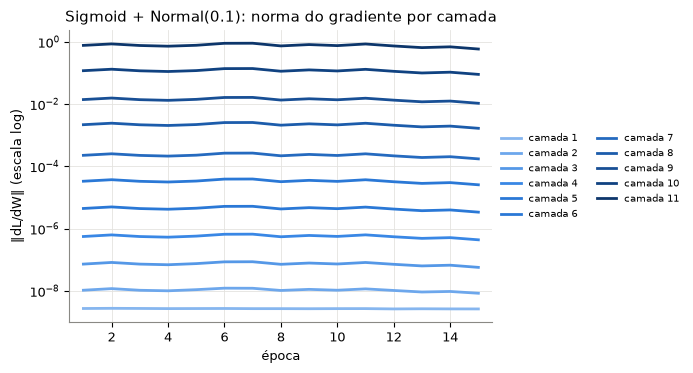

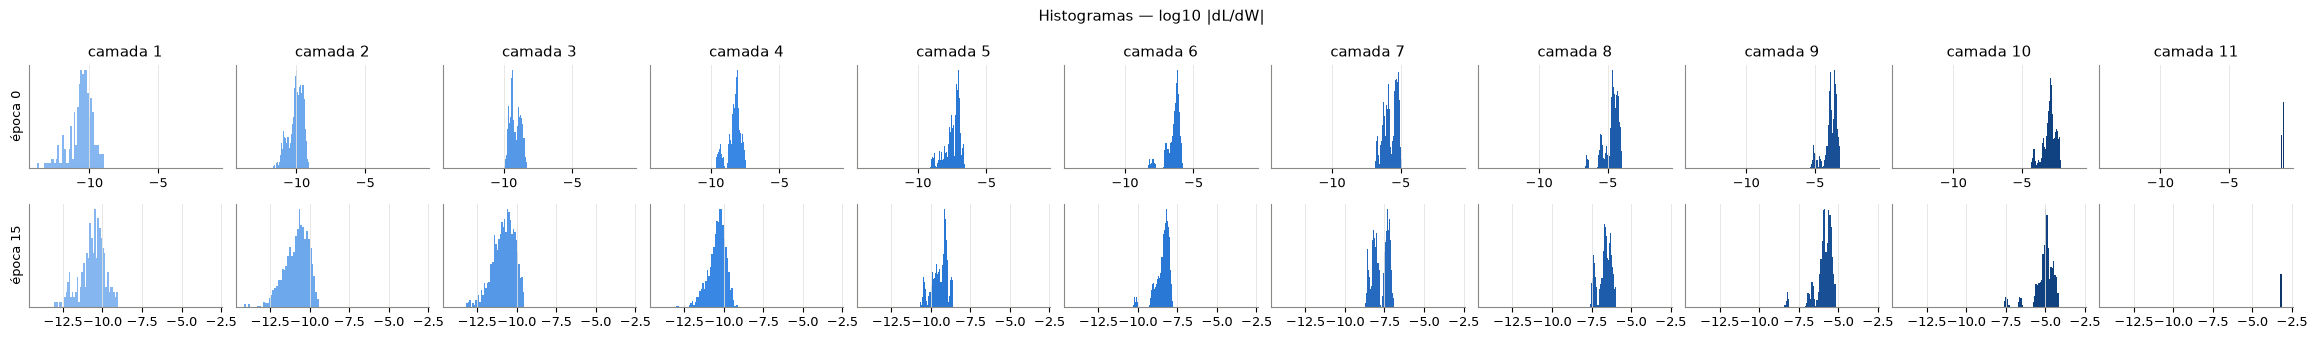

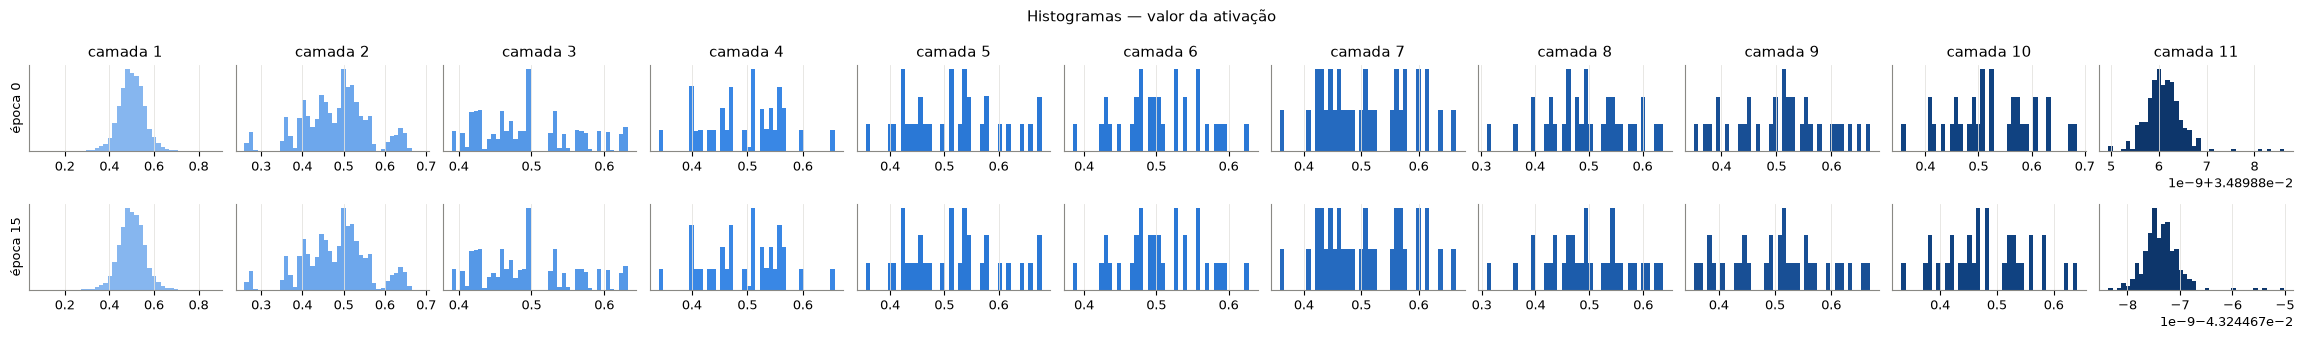

In [3]:
gg.plot_norma_grad_por_camada(hist_dissipa, "Sigmoid + Normal(0.1): norma do gradiente por camada")
gg.plot_histogramas(hist_dissipa, "grad_pesos", max_linhas=2)
gg.plot_histogramas(hist_dissipa, "ativacoes", max_linhas=2)

**Leitura.** As linhas das primeiras camadas (azul claro) ficam ~10⁹ vezes abaixo da última: as primeiras
camadas praticamente não aprendem e o R² fica em 0. Nos histogramas de log10|dL/dW|, a massa anda para a
esquerda à medida que se aproxima da entrada. As ativações da sigmoid ficam todas grudadas em ~0,5
(entrada pequena → sigmoid no meio, sem informação).

## 2. Correção da dissipação: ReLU + He

R² final na validação: 0.699


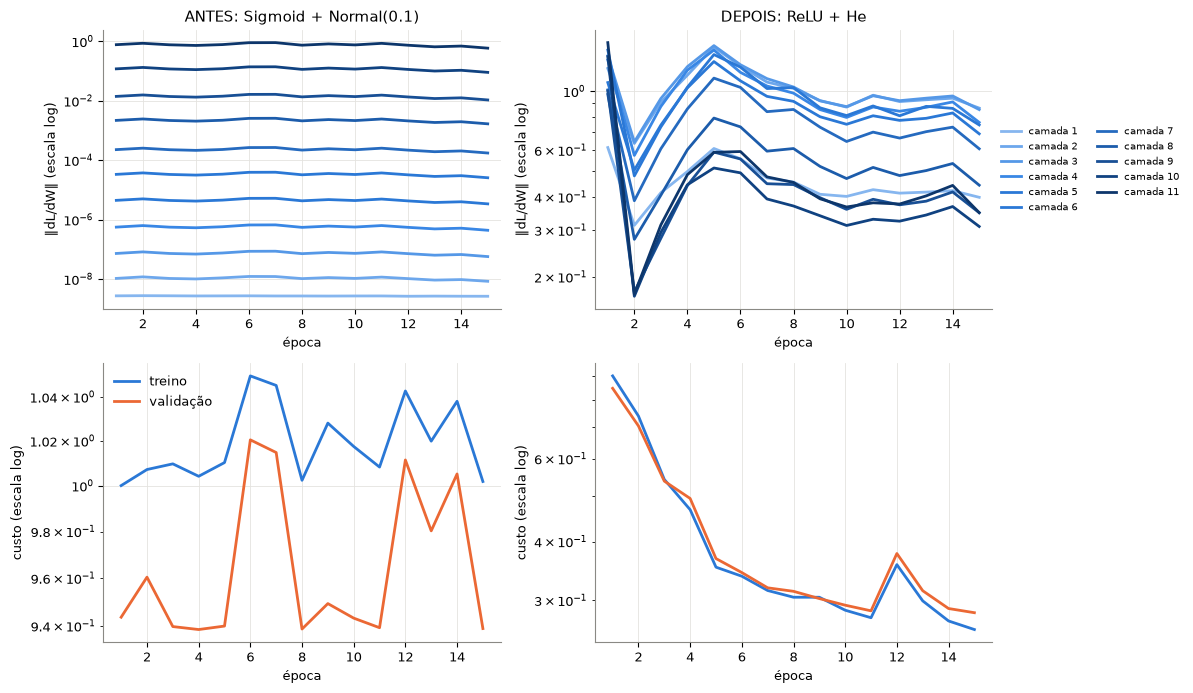

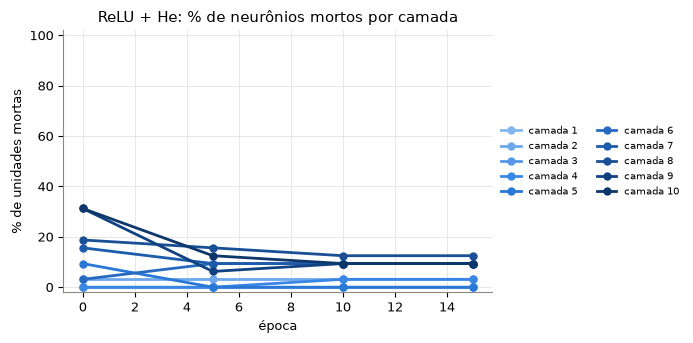

In [4]:
hist_relu_he = treinar(MLP(config_funda("relu", "he")), dados, dict(treino_sgd, taxa_aprendizado=0.01))
print(f"R² final na validação: {hist_relu_he['metrica_val'][-1]:.3f}")
gg.plot_antes_depois(hist_dissipa, hist_relu_he, "ANTES: Sigmoid + Normal(0.1)", "DEPOIS: ReLU + He")
gg.plot_relu_mortos(hist_relu_he, "ReLU + He: % de neurônios mortos por camada")

## 3. Explosão: ReLU + Normal(0, 1.0)

Agora os pesos são grandes demais. Como a explosão acontece em poucas **iterações**, o eixo x é a iteração (mini-lote).

In [5]:
hist_explode = treinar(MLP(config_funda("relu", "normal", 1.0)), dados,
                       dict(treino_sgd, taxa_aprendizado=1e-3))
print("custo nas primeiras iterações:", np.array(hist_explode["perda_passos"][:4]))

# Medir o fator de crescimento por camada no forward (rede recém-criada):
medias = [np.mean(np.abs(a)) for a in hist_explode["monitoramento"][0]["ativacoes"]]
fator = (medias[9] / medias[0]) ** (1 / 9)  # da camada 1 até a 10, são 9 multiplicações
print(f"previsão: ~√(32/2) = {np.sqrt(16):.1f}x por camada | medido: {fator:.1f}x por camada")

Treino DIVERGIU na época 1 (perda = nan). Parando.
custo nas primeiras iterações: [1.25604604e+012 4.98456559e+199             nan             nan]
previsão: ~√(32/2) = 4.0x por camada | medido: 4.3x por camada


**Leitura.** Cada camada multiplica o sinal por ~4 (como previsto), então a saída da rede já nasce ~10⁶ vezes
maior que a entrada, o custo começa em ~10¹² e o gradiente também. Um único passo de SGD com esse gradiente
joga os pesos para valores absurdos: na 2ª iteração o custo é ~10¹⁹⁹ e na 3ª passa do limite do float64 (`inf/NaN`).
A explosão é uma realimentação positiva: por isso acontece em poucas iterações, não aos poucos.

## 4. Correção da explosão: He + gradient clipping

Clipping por norma (`otimizadores.recortar_gradientes`): se ‖g‖ > 1, todos os gradientes são multiplicados
por 1/‖g‖. A direção não muda; só o tamanho do passo fica limitado.

Também testamos **só o clipping** com a init ruim: ele impede o NaN, mas a rede continua num ponto
péssimo — clipping é um cinto de segurança, não substitui uma boa inicialização.

He + clipping:            R² val = 0.631
Normal(1.0) + clipping:   R² val = -1.35e+11


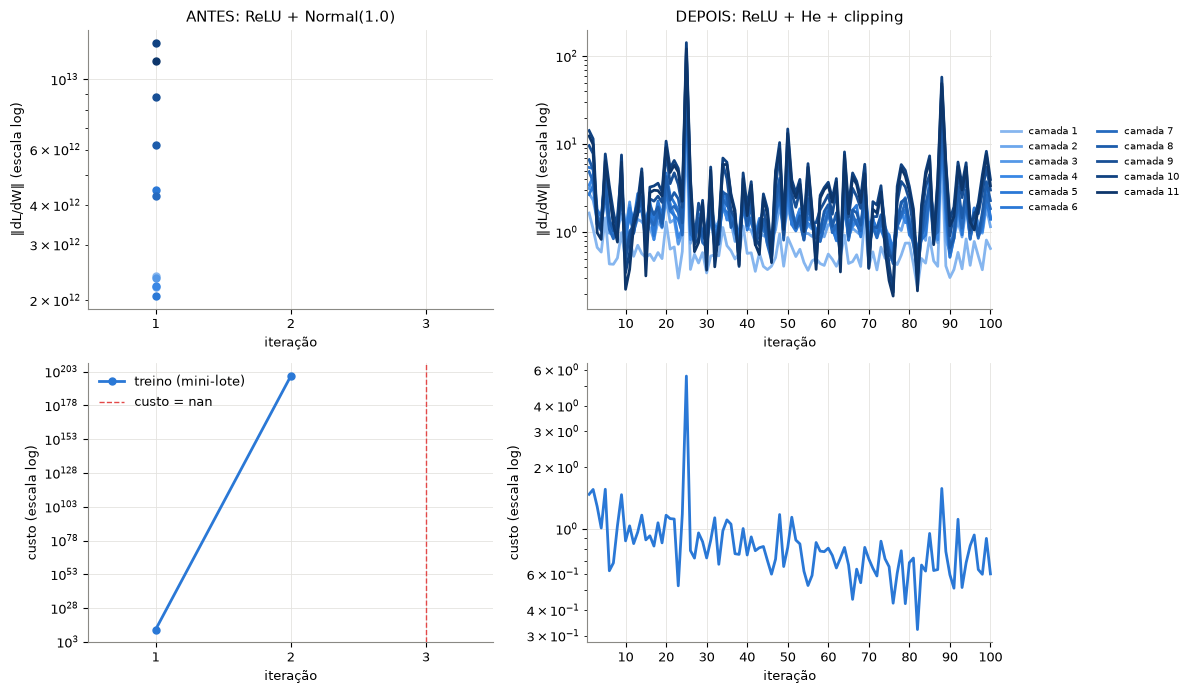

In [6]:
hist_he_clip = treinar(MLP(config_funda("relu", "he")), dados,
                       dict(treino_sgd, taxa_aprendizado=0.01, clip_norma=1.0))
hist_so_clip = treinar(MLP(config_funda("relu", "normal", 1.0)), dados,
                       dict(treino_sgd, taxa_aprendizado=1e-3, clip_norma=1.0))
print(f"He + clipping:            R² val = {hist_he_clip['metrica_val'][-1]:.3f}")
print(f"Normal(1.0) + clipping:   R² val = {hist_so_clip['metrica_val'][-1]:.3g}")
gg.plot_antes_depois(hist_explode, hist_he_clip, "ANTES: ReLU + Normal(1.0)", "DEPOIS: ReLU + He + clipping",
                    por_iteracao=True)

## 5. Visão geral: tudo em função da profundidade (rede recém-inicializada)

- **Forward:** com Normal(1.0) o sinal cresce exponencialmente camada a camada; com He ele fica estável.
- **Backward:** com sigmoid + pesos pequenos o gradiente despenca da saída para a entrada; com Normal(1.0)
  ele é ~10¹² em **todas** as camadas; com He fica perto de 1 em todas.

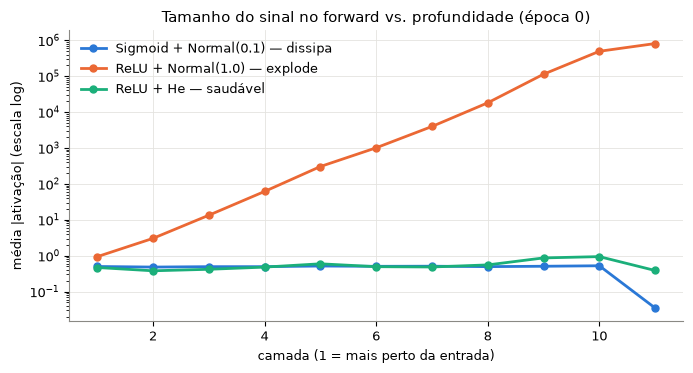

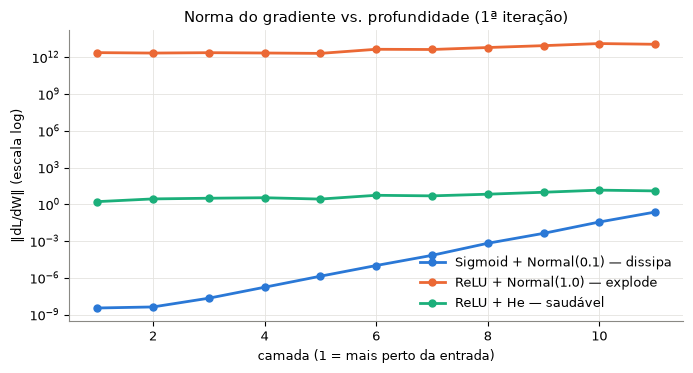

In [7]:
configuracoes = {
    "Sigmoid + Normal(0.1) — dissipa": hist_dissipa,
    "ReLU + Normal(1.0) — explode": hist_explode,
    "ReLU + He — saudável": hist_relu_he,
}
gg.plot_ativacao_vs_profundidade(configuracoes)
gg.plot_norma_vs_profundidade(configuracoes)

## Conclusões
- **Previsto e medido batem na ordem de grandeza:** com sigmoid e pesos pequenos, o gradiente da 1ª camada é ~10⁻⁹ do da última (0,25¹⁰ ≈ 10⁻⁶ vem só da sigmoid; os pesos pequenos fazem o resto).
- **Dissipação:** as primeiras camadas não aprendem e o R² fica em 0. **ReLU + He** mantém a norma do gradiente na mesma ordem em todas as camadas e a rede aprende.
- **Explosão:** com Normal(1.0) cada camada multiplica o sinal por ~4 (previsto √(32/2) = 4); a norma do gradiente já começa em ~10¹² e o custo vira `inf/NaN` em 3 iterações.
- **He + clipping** corrige; **só clipping** evita o NaN mas não salva uma inicialização ruim.
- Os histogramas de log10|dL/dW| deixam o fenômeno visível sem precisar olhar números.